### __K-Means Clustering with Real-World Data__

**Dataset:** Iris dataset (150 observations, 4 numeric measurements)  
**Algorithm:** K-Means  
**Evaluation:** Elbow method, Silhouette Score, and Davies-Bouldin Index

#### **1. Project overview**

K-Means is an unsupervised learning algorithm that partitions observations into a chosen number of clusters. It assigns each observation to the nearest cluster centroid and iteratively updates the centroids to reduce within-cluster variation.

In this notebook, I use the well-known **Iris dataset** from scikit-learn. It contains measurements of 150 iris flowers across four numeric features:

- Sepal length
- Sepal width
- Petal length
- Petal width

The dataset also contains species labels. These labels will **not** be used to fit K-Means; clustering will be performed using only the four measurements. The labels are available only for optional post-clustering comparison.

#### **Objectives**

1. Load and explore a real dataset.
2. Prepare and standardise the features.
3. Explore the data visually.
4. Use the elbow method to examine candidate values of K.
5. Fit and visualise a K-Means model.
6. Evaluate clustering using the Silhouette Score and Davies-Bouldin Index.
7. Interpret the results and discuss limitations.

> **Important:** K-Means uses distance calculations, so features measured on different scales can disproportionately influence the result. Standardisation is therefore applied before fitting the model.

### **2. Import libraries**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", None)
pd.set_option("display.precision", 3)

### **3. Define a consistent plotting style**

The `style_plot()` helper keeps the notebook's Matplotlib visualisations consistent. It supports titles, axis labels, grid styling, legends, and optional axis limits.

In [2]:
def style_plot(
    ax,
    title=None,
    xlabel=None,
    ylabel=None,
    title_fontsize=14,
    label_fontsize=11,
    remove_spines=True,
    grid=True,
    legend=True,
    xlim=None,
    ylim=None,
):
    """Apply a consistent style to a Matplotlib Axes object."""

    if title:
        ax.set_title(
            title,
            fontsize=title_fontsize,
            fontweight="bold",
            pad=15
        )

    if xlabel:
        ax.set_xlabel(xlabel, fontsize=label_fontsize)

    if ylabel:
        ax.set_ylabel(ylabel, fontsize=label_fontsize)

    if grid:
        ax.grid(
            True,
            linestyle="--",
            alpha=0.4,
            linewidth=0.3,
            color="gray"
        )

    if legend:
        ax.legend(fontsize=9)

    if remove_spines:
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        for spine in ax.spines.values():
            spine.set_linewidth(1.2)

    ax.set_facecolor("whitesmoke")

    if xlim:
        ax.set_xlim(xlim)

    if ylim:
        ax.set_ylim(ylim)

    return ax

### **4. Load the Iris dataset**

In [3]:
iris = load_iris()

# Build a DataFrame containing the four measurements
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Keep the species labels separately for optional evaluation only
species = pd.Series(
    iris.target,
    name="species",
    index=df.index
)

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [5]:
print(f"Number of observations: {df.shape[0]}")
print(f"Number of features: {df.shape[1]}")
print("\\nMissing values per feature:")
display(df.isna().sum().to_frame("missing_values"))

print("\nDescriptive statistics:")
display(df.describe().T)

Number of observations: 150
Number of features: 4
\nMissing values per feature:


,missing_values
sepal length (cm),0
sepal width (cm),0
petal length (cm),0
petal width (cm),0



Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
sepal length (cm),150.0,5.843,0.828,4.3,5.1,5.80,6.4,7.9
sepal width (cm),150.0,3.057,0.436,2.0,2.8,3.00,3.3,4.4
petal length (cm),150.0,3.758,1.765,1.0,1.6,4.35,5.1,6.9
petal width (cm),150.0,1.199,0.762,0.1,0.3,1.30,1.8,2.5


### **Dataset notes**

Each row represents one flower, and each feature is a measurement in centimetres. The dataset has four numeric features and 150 observations. The species labels are stored separately so they cannot accidentally enter the clustering feature matrix.

### **5. Explore feature distributions**

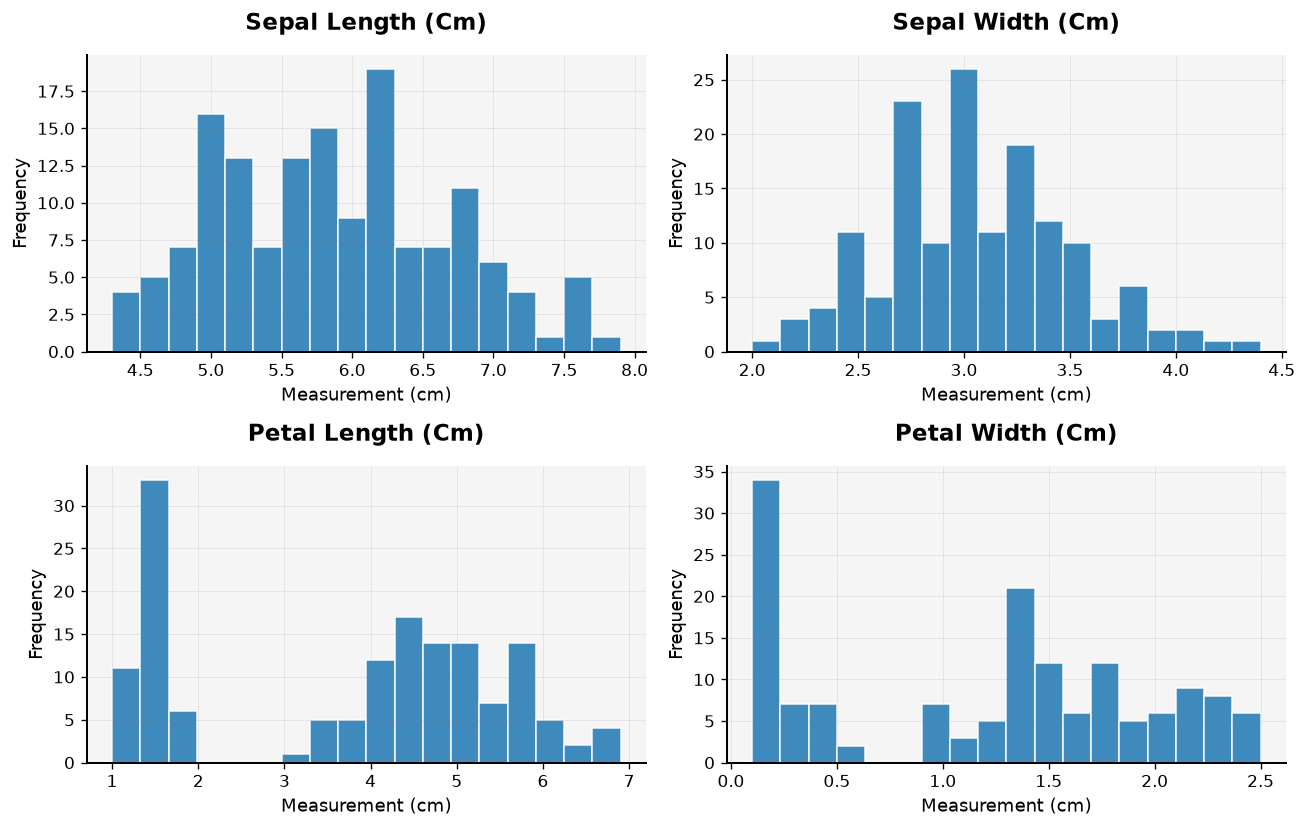

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), dpi=120)
axes = axes.flatten()

for ax, column in zip(axes, df.columns):
    ax.hist(df[column], bins=18, edgecolor="white", alpha=0.85)
    style_plot(
        ax,
        title=column.title(),
        xlabel="Measurement (cm)",
        ylabel="Frequency",
        legend=False
    )

plt.tight_layout()
plt.show()

### **6. Examine relationships between features**

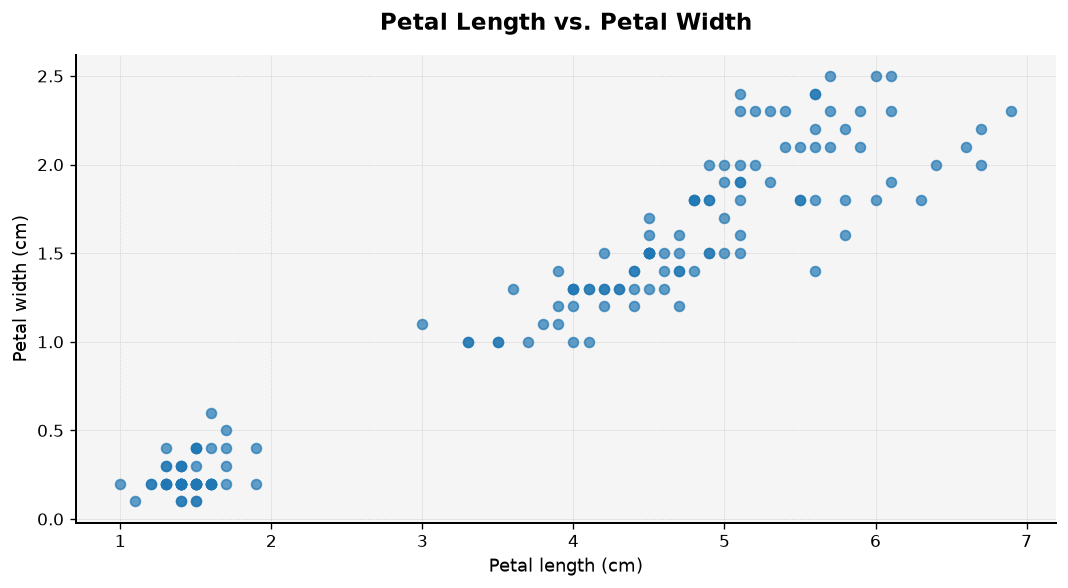

In [7]:
# Pairwise scatter plots, using two selected measurements
fig, ax = plt.subplots(figsize=(9, 5), dpi=120)

ax.scatter(
    df["petal length (cm)"],
    df["petal width (cm)"],
    s=35,
    alpha=0.7
)

style_plot(
    ax,
    title="Petal Length vs. Petal Width",
    xlabel="Petal length (cm)",
    ylabel="Petal width (cm)",
    legend=False
)

plt.tight_layout()
plt.show()

The scatter plot gives an initial view of the relationship between petal length and petal width. Visible groupings can motivate clustering, but the final model will use all four measurements rather than only the two shown here.

### **7. Standardise the features**

In [8]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

print("Scaled data shape:", X_scaled.shape)
print("Feature means (approximately zero):", np.round(X_scaled.mean(axis=0), 3))
print("Feature standard deviations (approximately one):", np.round(X_scaled.std(axis=0), 3))

Scaled data shape: (150, 4)
Feature means (approximately zero): [-0. -0. -0. -0.]
Feature standard deviations (approximately one): [1. 1. 1. 1.]


StandardScaler transforms each feature to have a mean near zero and a standard deviation near one. This prevents measurements with larger numerical scales from dominating Euclidean-distance calculations.

For a production prediction workflow, the scaler should be fitted on training data only and then applied to held-out data. Here, the exercise is exploratory clustering of one complete dataset.

### **8. Select a candidate number of clusters: Elbow method**

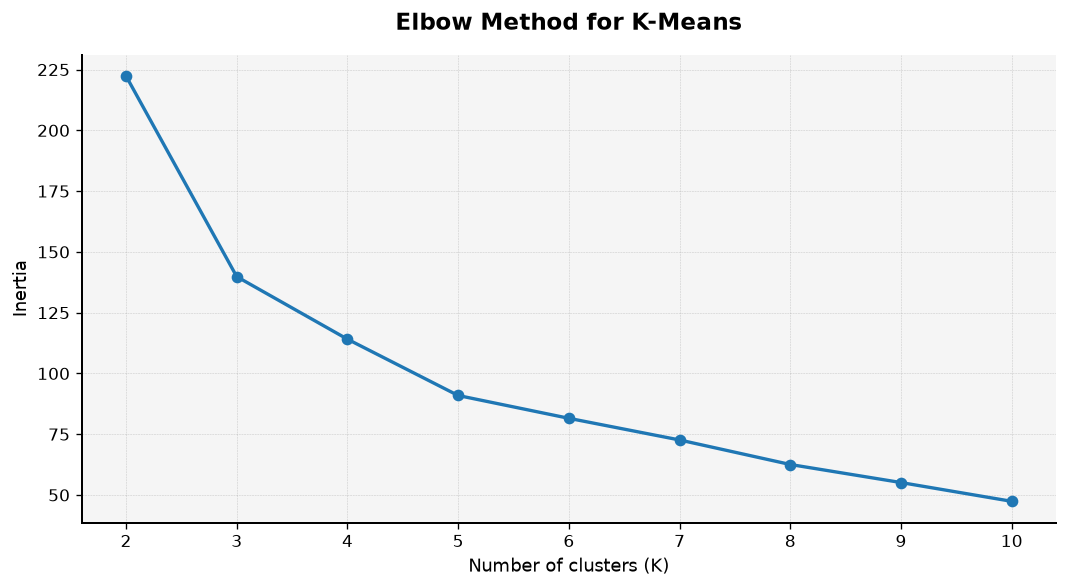

In [9]:
k_values = range(2, 11)
inertias = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_scaled)
    inertias.append(model.inertia_)

fig, ax = plt.subplots(figsize=(9, 5), dpi=120)

ax.plot(
    list(k_values),
    inertias,
    marker="o",
    linewidth=2
)

style_plot(
    ax,
    title="Elbow Method for K-Means",
    xlabel="Number of clusters (K)",
    ylabel="Inertia",
    legend=False
)

ax.set_xticks(list(k_values))
plt.tight_layout()
plt.show()

**How to read the elbow plot:** Inertia is the sum of squared distances from observations to their assigned centroids. It decreases as K increases, because more clusters can fit the data more closely. Look for a point where the reduction begins to slow. This is a heuristic, not proof that one K is objectively correct.

### **9. Compare cluster counts using evaluation metrics**

In [10]:
results = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = model.fit_predict(X_scaled)

    results.append({
        "K": k,
        "Inertia": model.inertia_,
        "Silhouette Score": silhouette_score(X_scaled, labels),
        "Davies-Bouldin Index": davies_bouldin_score(X_scaled, labels)
    })

metrics_df = pd.DataFrame(results)
display(metrics_df.round(4))

,K,Inertia,Silhouette Score,Davies-Bouldin Index
0,2,222.362,0.582,0.593
1,3,139.821,0.460,0.834
2,4,114.093,0.387,0.870
3,5,90.927,0.346,0.948
4,6,81.544,0.317,1.054
5,7,72.631,0.320,0.991
6,8,62.541,0.339,0.915
7,9,55.120,0.342,0.903
8,10,47.391,0.352,0.875


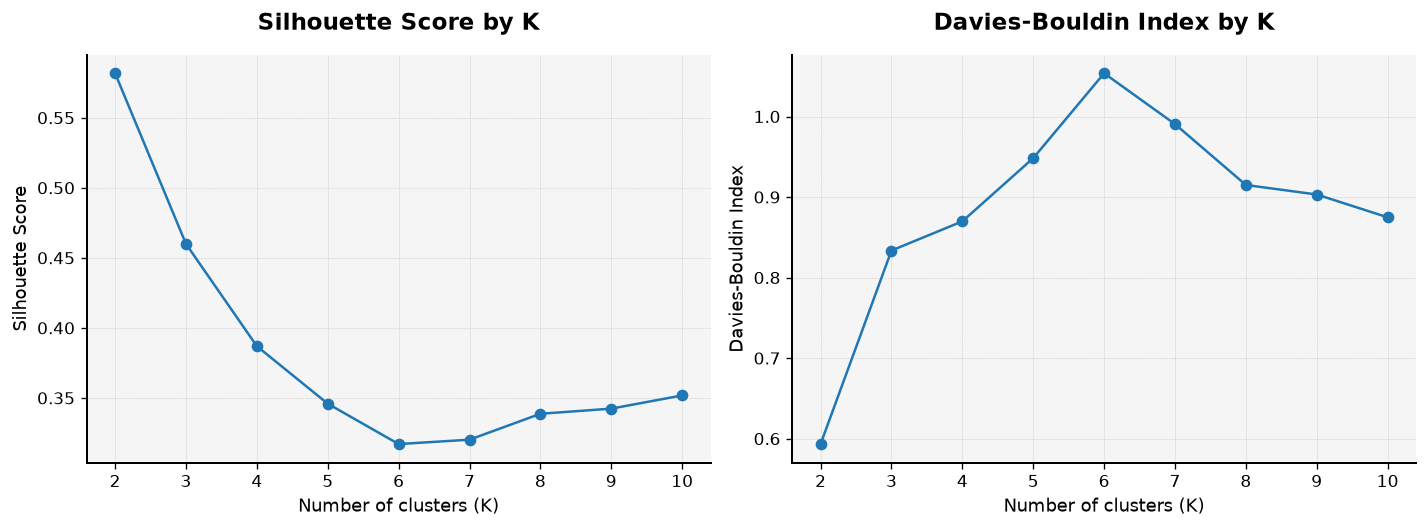

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), dpi=120)

axes[0].plot(
    metrics_df["K"],
    metrics_df["Silhouette Score"],
    marker="o"
)
style_plot(
    axes[0],
    title="Silhouette Score by K",
    xlabel="Number of clusters (K)",
    ylabel="Silhouette Score",
    legend=False
)
axes[0].set_xticks(metrics_df["K"])

axes[1].plot(
    metrics_df["K"],
    metrics_df["Davies-Bouldin Index"],
    marker="o"
)
style_plot(
    axes[1],
    title="Davies-Bouldin Index by K",
    xlabel="Number of clusters (K)",
    ylabel="Davies-Bouldin Index",
    legend=False
)
axes[1].set_xticks(metrics_df["K"])

plt.tight_layout()
plt.show()

### Understanding the evaluation metrics

**Silhouette Score**
- Range: -1 to +1.
- Higher values generally indicate observations are closer to their own cluster than to neighbouring clusters.
- Values near zero suggest overlapping clusters; negative values can indicate potentially unsuitable assignments.

**Davies-Bouldin Index**
- Lower values are preferred.
- It compares within-cluster dispersion with separation between clusters.
- A value closer to zero generally indicates more compact and better-separated clusters.

Neither metric should be interpreted using a universal pass/fail threshold. Compare candidate K values on the same feature representation and consider the practical purpose of the analysis.

## 10. Fit the final K-Means model

In [ ]:
# Set the candidate number of clusters after reviewing the plots and metrics.
# K=3 is a useful starting point for this dataset, but should be justified
# by the metric comparison above rather than assumed to be optimal.
best_k = 3

kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(X_scaled)

# Attach cluster assignments to a copy of the original measurements
clustered_df = df.copy()
clustered_df["cluster"] = cluster_labels

print("Cluster sizes:")
display(clustered_df["cluster"].value_counts().sort_index().to_frame("observations"))

## 11. Visualise clusters using PCA

In [ ]:
# Reduce the four standardised features to two dimensions for plotting.
# PCA is used only to create a 2D visualisation; K-Means was fitted
# using all four standardised features.
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

explained_variance = pca.explained_variance_ratio_.sum()
print(f"Variance explained by the first two PCs: {explained_variance:.2%}")

fig, ax = plt.subplots(figsize=(9, 6), dpi=120)

scatter = ax.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=cluster_labels,
    cmap="viridis",
    s=40,
    alpha=0.8
)

style_plot(
    ax,
    title=f"K-Means Clusters Visualised with PCA (K = {best_k})",
    xlabel="Principal Component 1",
    ylabel="Principal Component 2",
    legend=False
)

colorbar = fig.colorbar(scatter, ax=ax)
colorbar.set_label("Cluster")

plt.tight_layout()
plt.show()

PCA projects the four standardised features into two dimensions so that the cluster assignments can be visualised. The clustering itself was performed in the original four-dimensional scaled feature space. Therefore, some overlap in this 2D projection does not necessarily mean the clusters overlap to the same extent in the full feature space.

## 12. Visualise cluster centroids in the PCA projection

In [ ]:
# Project the fitted K-Means centroids into the same PCA space
centers_pca = pca.transform(kmeans.cluster_centers_)

fig, ax = plt.subplots(figsize=(9, 6), dpi=120)

for cluster_id in range(best_k):
    mask = cluster_labels == cluster_id

    ax.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        s=35,
        alpha=0.65,
        label=f"Cluster {cluster_id}"
    )

ax.scatter(
    centers_pca[:, 0],
    centers_pca[:, 1],
    marker="X",
    s=180,
    c="black",
    edgecolors="white",
    linewidths=1,
    label="Centroids",
    zorder=5
)

style_plot(
    ax,
    title=f"K-Means Clusters and Centroids (K = {best_k})",
    xlabel="Principal Component 1",
    ylabel="Principal Component 2"
)

ax.legend(title="Assignments", fontsize=9)
plt.tight_layout()
plt.show()

The centroid markers are the fitted cluster centres projected into the PCA plot. They are not recomputed in the two-dimensional PCA space; they are the original four-dimensional K-Means centroids transformed for display.

## 13. Evaluate the final clustering solution

In [ ]:
final_silhouette = silhouette_score(X_scaled, cluster_labels)
final_davies_bouldin = davies_bouldin_score(X_scaled, cluster_labels)

print(f"Number of clusters: {best_k}")
print(f"Silhouette Score: {final_silhouette:.4f}")
print(f"Davies-Bouldin Index: {final_davies_bouldin:.4f}")

### Interpreting the final metrics

Use the values printed above to describe the fitted solution:

- A higher Silhouette Score indicates stronger separation between each observation's own cluster and the nearest alternative cluster.
- A lower Davies-Bouldin Index indicates a more favourable balance of cluster compactness and separation.

Do not describe a score as “good” or “poor” based on a universal cutoff. Compare it with the other K values in the metric table, inspect the visualisation, and consider whether the resulting cluster sizes and profiles are useful.

## 14. Profile the clusters

In [ ]:
cluster_profile = (
    clustered_df
    .groupby("cluster")
    .agg(["mean", "median", "count"])
)

display(cluster_profile.round(2))

Cluster profiles help explain how the groups differ in the original measurement units. For interpretation, compare the mean or median of each feature across clusters. The cluster numbers are arbitrary identifiers: Cluster 0 is not inherently better, larger, or more important than Cluster 1.

## 15. Optional: Compare clusters with the known species labels

In [ ]:
# This is an external descriptive comparison only.
# Species labels were not used to fit K-Means.
comparison = pd.crosstab(
    pd.Series(species.map(dict(enumerate(iris.target_names))), name="Actual species"),
    pd.Series(cluster_labels, name="K-Means cluster")
)

display(comparison)

The cross-tabulation compares the unsupervised cluster assignments with the dataset's known species labels. It can help assess whether the clusters align with the known categories, but the species labels were deliberately excluded from model fitting. Cluster IDs are arbitrary, so a cluster number does not correspond directly to a species name.

## 16. Conclusion

This notebook applied K-Means clustering to the four numeric measurements in the Iris dataset. The features were standardised before fitting because K-Means relies on distance calculations. The elbow method, Silhouette Score, and Davies-Bouldin Index were used to examine candidate cluster counts, while PCA provided a two-dimensional view of the resulting assignments.

The final choice of K should be supported by the metric comparison, cluster profiles, and the intended use of the groups. No single evaluation metric is sufficient on its own. The optional species comparison provides external context but does not change the unsupervised nature of the clustering exercise.

### Limitations

- K-Means requires the number of clusters to be specified in advance.
- It is sensitive to feature scaling, outliers, and initial centroid placement.
- It works best when clusters are reasonably compact and roughly spherical under the chosen distance measure.
- The Iris dataset is small and relatively clean; performance on larger, noisier real-world datasets may differ.
- PCA is a visualisation aid and can hide structure present in the full feature space.

### Possible next steps

- Compare K-Means with hierarchical clustering and DBSCAN.
- Examine sensitivity to different random seeds and initialisations.
- Investigate cluster stability and the effect of outliers.
- Repeat the workflow on a larger applied dataset.